# Exercise 4.3.11
Let $\mathbb X = \mathbb R^N$, $\mathbb Y = \mathbb R^M$, $y \in \mathbb Y$ and $A \in \mathbb R^{M \times N}$. Consider $f(x) = \tfrac{1}{2} \| A x - y \|^2_{\mathbb Y}$. 

(i) Compute $\nabla f$ and $\nabla^2 f$. Provide a new meaning to the normal equation (Corollary 2.1.5). 

(ii) Implement a function that performs $K$ iterations of gradient descent (Algorithm 1) with initialization $x_0 \in \mathbb R^N$. It should return the last iterate $x_K$, the (relative) measurement errors $\{ f(x_k) / f(0) \}_{k = 0}^K$ and the relative errors $\{\|x_k - x_*\| / \| x_* \| \}_{k =0}^K$ for a given $x_*$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def gradient_descent(x0, nu, grad, loss, num_iter, xt = None):
    x = x0
    loss_base = loss(np.zeros_like(x0))
    m_error = np.zeros((num_iter + 1))
    
    m_error[0] = loss(x0) / loss_base
    
    if xt is not None:
        error = np.zeros((num_iter + 1))
        error[0] = np.linalg.norm(x-xt) / np.linalg.norm(xt)

    for k in range(num_iter):
        x = x - nu* grad(x)

        m_error[k+1] = loss(x) / loss_base
        if xt is not None:
            error[k+1] = np.linalg.norm(x-xt) / np.linalg.norm(xt)

    if xt is not None:
        return x, m_error, error
    else:
        return x, m_error

(iii) Let $N$ be even. Consider a deconvolution problem with convolution kernel $g^\alpha \in \mathbb R^N$, $0 < \alpha < 1$ whic is implicitly given via
$$
(F g^{\alpha})_k = 
\begin{cases}
    1 - (1 - \alpha)\frac{k}{N/2 - 1}, & k = 0, \ldots, N/2 - 1 \\
    \alpha + (1 - \alpha)\frac{k - N/2}{N/2 - 1} & k = N/2, \ldots, N -1.
\end{cases} 
$$
For the convolution matrix $A = C(g)$ (see Exercise Sheet 1), find the spectral norm $\|A\|_{2}$ and the condition number $\kappa(A) = \frac{\sigma_{max}(A)}{\sigma_{min}(A)}$. Implement a function the computes $g^\alpha$, $Fg^\alpha$ for given $N$ and $\alpha$.  

In [3]:
def generate_window(N,kappa = 1e-2):
    g_hat = np.linspace(kappa, 1, N//2)
    if N % 2 == 0:
        g_hat = np.concatenate((np.flip(g_hat),g_hat))
    else:
        g_hat = np.concatenate((np.flip(g_hat),g_hat[1:]))
    g = np.fft.ifft(g_hat)
    return g, g_hat

The spectral norm is $\|C(g)\|_2 = \|F_N g\|_\infty = 1$ and the condition number is $\kappa(C(g)) = \|F_N g\|_\infty / \min_{j} |(F_N g)_j| = \alpha^{-1}$. 

(iv)  Let $N = 200$, $x_* \in \mathbb R^N$ with entries
$$
(x_*)_k = \sin(2 \pi k / N) + 0.5 \sin(6 \pi k / N)  - 0.2 \sin(40 \pi k / N) + 0.3 \sin(10 \pi k / N),
\quad k = 0, \ldots, N-1,
$$
As associated (noisy) data, we consider $y = C(g^\alpha) x_* + 0.01\mathcal N(0,I_N)$, where $\mathcal N(0,I_N)$ is a standard Gaussian random variable.
For $\alpha = 10^{- k/2}$, $k = 1, \ldots, 5 $, perform $K =10000$ iterations of gradient descent with initialization $x_0 \sim \mathcal N(0,I_N)$.
Plot the resulting errors (in $\log_{10}$ scale). What do you observe?  
    

In [4]:
def convolve(f,g):
    f_fft = np.fft.fft(f)
    g_fft = np.fft.fft(g)    
    conv = np.fft.ifft(f_fft * g_fft)
    return conv

def pseudoinv(y,g):
    N = g.shape[0]
    g_fft = np.fft.fft(g)
    
    idx_g = np.abs(g_fft) > 0
    inv_g_fft = np.zeros((N), dtype = complex)
    inv_g_fft[idx_g] = 1.0/ g_fft[idx_g]    
    
    f_dagger = np.fft.ifft(inv_g_fft * np.fft.fft(y))
    return f_dagger

In [5]:
N = 200
idx = np.arange(N)

f = np.sin( 2 * np.pi * idx / N) + 0.5 *np.sin( 6 * np.pi * idx / N) 
f = f - 0.2 * np.sin( 40 * np.pi * idx / N) + 0.3 * np.sin( 10 * np.pi * idx / N)

K = 5
num_iter = 10000
errors = np.zeros((K,num_iter+1))
m_errors = np.zeros((K,num_iter+1))
kappas = []
for k in range(K):
    kappa = 10**-(0.5*(k+1))
    kappas += [f"kappa = {1.0/kappa:.2f}"]
    g, g_hat = generate_window(N,kappa)
    A = lambda x: convolve(x,g)
    AT = A
    conv = A(f) + 0.01 * np.random.randn(N)
    grad = lambda x: AT( A(x) - conv)
    loss = lambda x: 0.5 * np.linalg.norm(A(x) - conv)**2
    nu = 1.0 / np.max(np.abs(g_hat))**2 
    x0 = np.random.randn((N))

    x_gd, m_err, err = gradient_descent(x0,nu,grad,loss,num_iter,f)
    errors[k,:] = err
    m_errors[k,:] = m_err

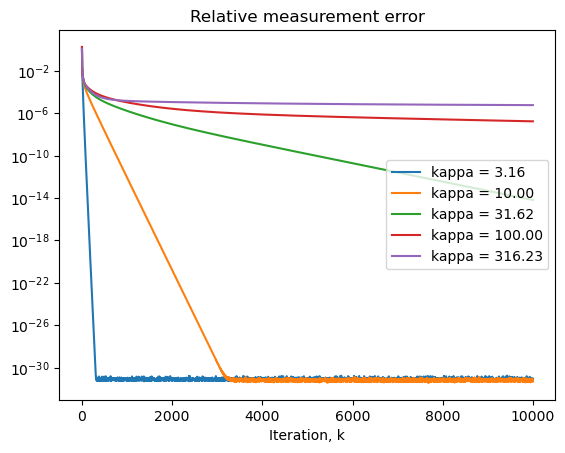

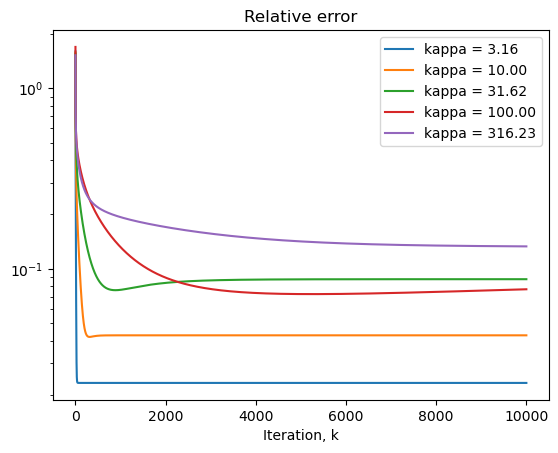

In [6]:
plt.semilogy(m_errors.T)
plt.legend(kappas, loc = 'center right')
plt.title('Relative measurement error')
plt.xlabel('Iteration, k')
plt.show()

plt.semilogy(errors.T)
plt.legend(kappas, loc = 'upper right')
plt.title('Relative error')
plt.xlabel('Iteration, k')
plt.show()

(v) Implement accelerated gradient descent (Algorithm 2) and perform the reconstructions in (iv) again.
Does the convergence behavior improve?

In [7]:
def accelerated_gradient_descent(x0, nu, grad, loss, num_iter, xt = None):
    x = x0
    func_val = np.zeros((num_iter + 1))
    loss_base = loss(np.zeros_like(x0))
    func_val[0] = loss(x0) / loss_base 
    z = x0
    
    if xt is not None:
        error = np.zeros((num_iter + 1))
        error[0] = np.linalg.norm(x-xt) / np.linalg.norm(xt)

    for k in range(num_iter):
        x_old = x
        theta = 2.0/(2 + k)
        u = (1 - theta)*x + theta*z
        x = u - nu* grad(u)
        z = x_old + (x - x_old) / theta
        
        func_val[k+1] = loss(x) / loss_base
        if xt is not None:
            error[k+1] = np.linalg.norm(x-xt) / np.linalg.norm(xt)
                  
    if xt is not None:
        return x, func_val, error
    else:
        return x, func_val

In [8]:
K = 5
num_iter = 10000
errors_ac = np.zeros((K,num_iter+1))
m_errors_ac = np.zeros((K,num_iter+1))
kappas = []
for k in range(K):
    kappa = 10**-(0.5*(k+1))
    kappas += [f"kappa = {1.0/kappa:.2f}"]
    g, g_hat = generate_window(N,kappa)
    A = lambda x: convolve(x,g)
    AT = A
    conv = A(f) + 0.01 * np.random.randn(N)
    grad = lambda x: AT( A(x) - conv)
    loss = lambda x: 0.5 * np.linalg.norm(A(x) - conv)**2
    nu = 1.0 / np.max(np.abs(g_hat))**2 
    x0 = np.random.randn((N))

    x_gd, m_err, err = accelerated_gradient_descent(x0,nu,grad,loss,num_iter,f)
    errors_ac[k,:] = err
    m_errors_ac[k,:] = m_err

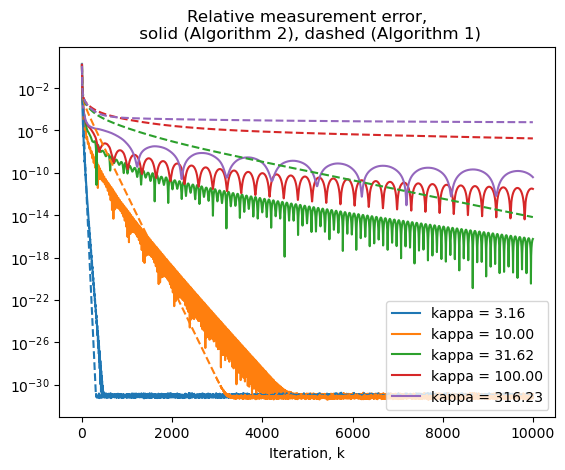

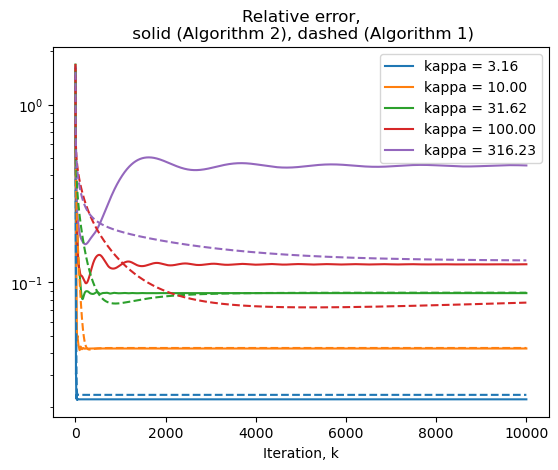

In [9]:
plt.semilogy(m_errors_ac.T)
plt.gca().set_prop_cycle(None)
plt.semilogy(m_errors.T, '--')
plt.legend(kappas, loc = 'lower right')
plt.title('Relative measurement error,\n solid (Algorithm 2), dashed (Algorithm 1)')
plt.xlabel('Iteration, k')
plt.show()

plt.semilogy(errors_ac.T)
plt.gca().set_prop_cycle(None)
plt.semilogy(errors.T, '--')
plt.legend(kappas, loc = 'upper right')
plt.title('Relative error,\n solid (Algorithm 2), dashed (Algorithm 1)')
plt.xlabel('Iteration, k')
plt.show()